# 07exposure: how many people breathed the haze

Part B of PF5. Combines the daily GEOS-FP PM2.5 of the season (`05season`) with WorldPop population maps.

| Section | What |
|---|---|
| 2 | Download WorldPop 1 km population maps (2020) for eight countries; about 100 to 200 MB, a few minutes |
| 3 | Add the population up on the smoke grid (0.5 x 0.625 degrees), per country |
| 4 | Daily exposure per country, four ways: total PM2.5 and fire smoke, each as the model gives it and adjusted with the ground check |
| 5 | Charts and maps |

**Levels (24-hour PM2.5, micrograms per m3):** 15 = WHO guideline; 35.5 = US AQI "unhealthy for sensitive groups" starts; 55.5 = US AQI "unhealthy" starts.

**Four versions, because of what the ground check (`08groundcheck`) found:**

- **Total PM2.5** is what people breathe, but in big cities (Jakarta, West Java) much of it is the city's own traffic and industry, not haze.
- **Fire smoke** is measured with GEOS-FP's **brown carbon**, a tracer that only comes from fires: it is close to zero in non-haze cities such as Bangkok and Guangzhou, but makes up about 80% of the smoke carbon at Palangka Raya. Ordinary organic carbon also comes from traffic, industry and plants, which is why Jakarta looked "smoky" when all carbon was counted. Brown carbon leaves out the fires' black carbon, so it is a slightly low estimate of fire smoke.
- **As the model gives it** versus **adjusted**: against Singapore's official stations GEOS-FP read about 1.8 times too high (the factor is read from `08groundcheck`'s results). The adjusted version divides by that factor. The truth is most likely between the two, so the case study quotes a range. (The factor comes from one city; near the fires, in Palembang, the model read too low, so the adjustment is a sensitivity check, not a correction.)

**Other limits.** Population is for 2020 (the latest year of WorldPop's standard global 1 km series), so 2026 numbers are somewhat higher. PM2.5 is the GEOS-FP model at about 55 km resolution, so a city's value is an average over its grid cell. Run `08groundcheck` before this notebook.

## Section 0: settings

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
SEASON_DIR = PROJECT_DIR / "data" / "processed" / "season"
POP_DIR = PROJECT_DIR / "data" / "raw" / "worldpop"
COAST_DIR = PROJECT_DIR / "data" / "raw" / "naturalearth"
FIG_DIR = SEASON_DIR / "figures"

POP_YEAR = 2020  # <- WorldPop year (2000 to 2020 available in this series)
COUNTRIES = {"IDN": "Indonesia", "MYS": "Malaysia", "SGP": "Singapore", "BRN": "Brunei", "PHL": "Philippines", "THA": "Thailand", "TLS": "Timor-Leste", "PNG": "Papua New Guinea"}  # <-
LEVELS = {"WHO guideline (15)": 15.0, "Unhealthy for sensitive groups (35.5)": 35.5, "Unhealthy (55.5)": 55.5}  # <-
ADJUST_FACTOR = None  # <- None = mean model/station ratio for Singapore from 08groundcheck; or set a number, for example 1.8
MAIN_COUNTRIES = ["IDN", "MYS", "SGP", "BRN"]  # <- VISUAL: countries drawn as lines (all are in the tables)
COUNTRY_COLORS = {"IDN": "#e34948", "MYS": "#2a78d6", "SGP": "#e87ba4", "BRN": "#1baf7a", "Others": "#a8a7a2"}  # <- VISUAL
MAP_EXTENT = (94.0, 128.0, -9.0, 12.0)  # <- VISUAL: map of person-days

## Section 1: imports and data

In [3]:
import json
import requests
import numpy as np
import pandas as pd
import xarray as xr
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

POP_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.facecolor"] = "#fcfcfb"
plt.rcParams["axes.facecolor"] = "#fcfcfb"
plt.rcParams["axes.edgecolor"] = "#a8a7a2"
plt.rcParams["font.size"] = 10

geos = xr.open_dataset(SEASON_DIR / "geosfp_daily.nc")[["pm25", "brsmass"]].load()
geos = geos.rename({"brsmass": "firesmoke"})
DAYS = pd.to_datetime(geos.time.values)
G_LAT = geos.lat.values
G_LON = geos.lon.values
DLAT = G_LAT[1] - G_LAT[0]
DLON = G_LON[1] - G_LON[0]
LAT_EDGES = np.r_[G_LAT - DLAT / 2, G_LAT[-1] + DLAT / 2]
LON_EDGES = np.r_[G_LON - DLON / 2, G_LON[-1] + DLON / 2]
print("Smoke grid:", len(G_LAT), "x", len(G_LON), f"({DLAT:g} x {DLON:g} deg), days:", len(DAYS))

Smoke grid: 121 x 113 (0.5 x 0.625 deg), days: 86


## Section 2: WorldPop population maps

Files go to `data/raw/worldpop/` and are only downloaded once. Each pixel holds the estimated number of people living in that 1 km square.

In [4]:
BASE = f"https://data.worldpop.org/GIS/Population/Global_2000_2020_1km/{POP_YEAR}"
for iso in COUNTRIES:
    path = POP_DIR / f"{iso.lower()}_ppp_{POP_YEAR}_1km_Aggregated.tif"
    if path.exists() and path.stat().st_size > 0:
        print(f"{iso}: already there ({path.stat().st_size / 1e6:.1f} MB)")
        continue
    url = f"{BASE}/{iso}/{path.name}"
    with requests.get(url, stream=True, timeout=300) as r:
        print(f"{iso}: HTTP {r.status_code}", end="")
        r.raise_for_status()
        with open(path, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    print(f", {path.stat().st_size / 1e6:.1f} MB")

IDN: already there (11.3 MB)
MYS: already there (2.0 MB)
SGP: already there (0.0 MB)
BRN: already there (0.0 MB)
PHL: already there (2.0 MB)
THA: already there (3.1 MB)
TLS: already there (0.1 MB)
PNG: already there (2.7 MB)


## Section 3: population on the smoke grid

Every 1 km pixel is added to the smoke grid cell that contains its centre, separately for each country. The totals are printed so they can be checked against official figures (for example, Indonesia about 270 million and Malaysia about 32 million in 2020).

In [5]:
pop_grids = {}
rows = []
for iso, name in COUNTRIES.items():
    path = POP_DIR / f"{iso.lower()}_ppp_{POP_YEAR}_1km_Aggregated.tif"
    with rasterio.open(path) as src:
        pop = src.read(1).astype("float64")
        nodata = src.nodata
        t = src.transform
    if nodata is not None:
        pop[pop == nodata] = 0
    pop[~np.isfinite(pop) | (pop < 0)] = 0
    ny, nx = pop.shape
    lon_c = t.c + t.a * (np.arange(nx) + 0.5)
    lat_c = t.f + t.e * (np.arange(ny) + 0.5)
    grid = np.zeros((len(G_LAT), len(G_LON)))
    for r0 in range(0, ny, 500):
        block = pop[r0:r0 + 500]
        lat_b = np.repeat(lat_c[r0:r0 + 500], nx)
        lon_b = np.tile(lon_c, block.shape[0])
        w = block.ravel()
        keep = w > 0
        h, _, _ = np.histogram2d(lat_b[keep], lon_b[keep], bins=[LAT_EDGES, LON_EDGES], weights=w[keep])
        grid += h
    total = pop.sum()
    inside = grid.sum()
    pop_grids[iso] = grid
    rows.append({"country": name, "population_millions": total / 1e6, "inside_study_box_pct": 100 * inside / total if total else np.nan})
pop_table = pd.DataFrame(rows).set_index("country")
print(f"WorldPop {POP_YEAR} population:")
print(pop_table.round(2).to_string())
pop_da = xr.DataArray(np.stack([pop_grids[i] for i in COUNTRIES]), coords={"country": list(COUNTRIES), "lat": G_LAT, "lon": G_LON}, dims=["country", "lat", "lon"], name="population")
pop_da.to_netcdf(SEASON_DIR / f"population_grid_{POP_YEAR}.nc")

WorldPop 2020 population:
                  population_millions  inside_study_box_pct
country                                                    
Indonesia                      284.21                 100.0
Malaysia                        34.80                 100.0
Singapore                        4.56                 100.0
Brunei                           0.46                 100.0
Philippines                    110.19                 100.0
Thailand                        75.21                 100.0
Timor-Leste                      1.42                 100.0
Papua New Guinea                 9.26                 100.0


## Section 4: daily exposure per country, four versions

In [6]:
stats_file = SEASON_DIR / "groundcheck_stats.csv"
if ADJUST_FACTOR is None:
    gc = pd.read_csv(stats_file)
    sg_rows = gc[gc["place"].str.startswith("Singapore")]
    factor = float(sg_rows["ratio"].mean())
    print(f"Adjustment factor from 08groundcheck: model / Singapore stations = {factor:.2f} (mean of {len(sg_rows)} regions, range {sg_rows['ratio'].min():.2f} to {sg_rows['ratio'].max():.2f})")
else:
    factor = float(ADJUST_FACTOR)
    print(f"Adjustment factor set by hand: {factor:.2f}")

FIELDS = {}
FIELDS["Total PM2.5, model"] = geos["pm25"].values
FIELDS["Total PM2.5, adjusted"] = geos["pm25"].values / factor
FIELDS["Fire smoke, model"] = geos["firesmoke"].values
FIELDS["Fire smoke, adjusted"] = geos["firesmoke"].values / factor

rec = []
for field, arr in FIELDS.items():
    for iso, name in COUNTRIES.items():
        p = pop_grids[iso]
        if p.sum() == 0:
            continue
        for i, day in enumerate(DAYS):
            v = arr[i]
            ok = np.isfinite(v)
            row = {"field": field, "date": day, "iso": iso, "country": name}
            row["pop_weighted"] = float((v[ok] * p[ok]).sum() / p[ok].sum())
            for label, lev in LEVELS.items():
                row[label] = float(p[ok & (v >= lev)].sum())
            rec.append(row)
exposure = pd.DataFrame(rec)
exposure.to_csv(SEASON_DIR / "exposure_daily.csv", index=False)

unh = "Unhealthy (55.5)"
g = exposure.groupby(["field", "country"])
summary = pd.DataFrame({"mean_pop_weighted": g["pop_weighted"].mean(), "worst_day_unhealthy_millions": g[unh].max() / 1e6, "person_days_unhealthy_millions": g[unh].sum() / 1e6, "person_days_over_WHO_millions": g["WHO guideline (15)"].sum() / 1e6}).reset_index()
summary.round(2).to_csv(SEASON_DIR / "exposure_summary.csv", index=False)
order = [COUNTRIES[i] for i in COUNTRIES]
for col, title in [("mean_pop_weighted", "Season mean of population-weighted PM2.5 (micrograms per m3)"), ("worst_day_unhealthy_millions", "Worst day: millions of people in 'unhealthy' air (at least 55.5)"), ("person_days_unhealthy_millions", "Season: million person-days in 'unhealthy' air")]:
    print(title)
    print(summary.pivot(index="country", columns="field", values=col).loc[order, list(FIELDS)].round(1).to_string())
    print()
monthly = exposure[exposure["field"] == "Fire smoke, model"].assign(month=lambda d: d["date"].dt.strftime("%B")).pivot_table(index="country", columns="month", values="pop_weighted", aggfunc="mean")
monthly = monthly[[m for m in ["August", "September", "October"] if m in monthly.columns]].loc[order]
print("Monthly population-weighted FIRE SMOKE (brown carbon), model (micrograms per m3):")
print(monthly.round(1).to_string())

Adjustment factor from 08groundcheck: model / Singapore stations = 1.80 (mean of 5 regions, range 1.45 to 2.35)
Season mean of population-weighted PM2.5 (micrograms per m3)
field             Total PM2.5, model  Total PM2.5, adjusted  Fire smoke, model  Fire smoke, adjusted
country                                                                                             
Indonesia                       44.2                   24.5               12.4                   6.9
Malaysia                        55.2                   30.6               21.6                  12.0
Singapore                       88.3                   49.0               28.9                  16.0
Brunei                          39.3                   21.8               18.2                  10.1
Philippines                     22.0                   12.2                4.8                   2.7
Thailand                        21.2                   11.8                0.9                   0.5
Timor-Leste        

## Section 5: charts and map

1. Population-weighted daily values for the main countries: total PM2.5 (top) and fire smoke (bottom); the line is the model, the band reaches down to the adjusted value.
2. Season person-days in "unhealthy" air per country in all four versions (the range to quote).
3. Maps for fire smoke: unhealthy days per place, and person-days (people in a grid cell times its number of days with fire smoke at the unhealthy level).

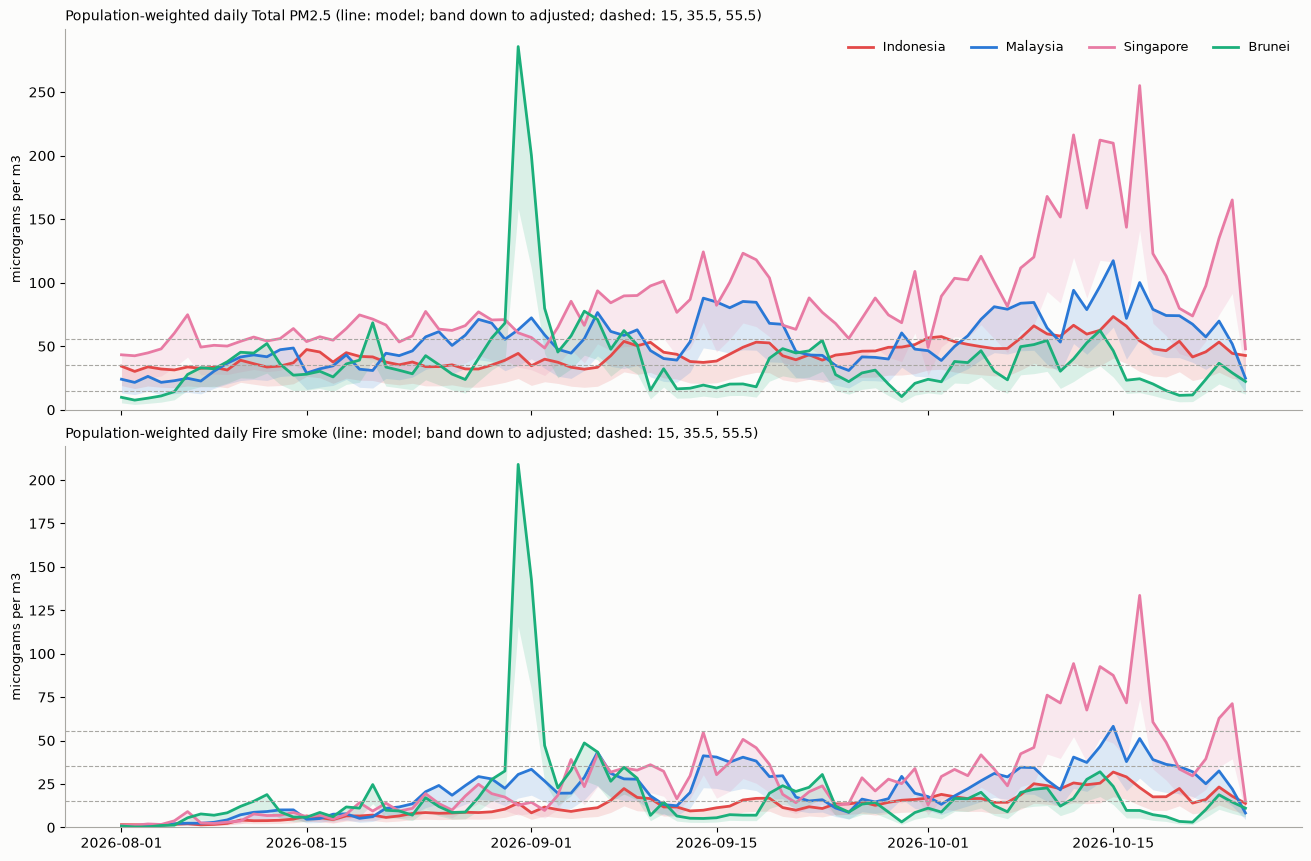

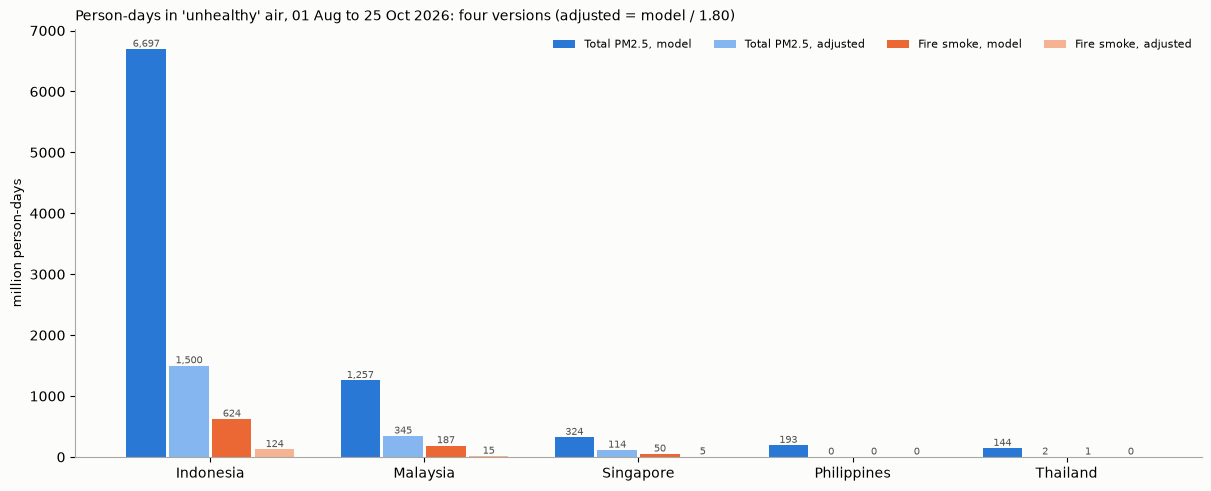

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True, constrained_layout=True)
for ax, kind in zip(axes, ["Total PM2.5", "Fire smoke"]):
    for iso in MAIN_COUNTRIES:
        m = exposure[(exposure["iso"] == iso) & (exposure["field"] == f"{kind}, model")]
        a = exposure[(exposure["iso"] == iso) & (exposure["field"] == f"{kind}, adjusted")]
        ax.plot(m["date"], m["pop_weighted"], color=COUNTRY_COLORS[iso], lw=2, label=COUNTRIES[iso])
        ax.fill_between(m["date"], a["pop_weighted"].values, m["pop_weighted"].values, color=COUNTRY_COLORS[iso], alpha=0.15, lw=0)
    for lev in LEVELS.values():
        ax.axhline(lev, color="#a8a7a2", lw=0.8, ls="--")
    ax.set_ylabel("micrograms per m3", fontsize=9)
    ax.set_title(f"Population-weighted daily {kind} (line: model; band down to adjusted; dashed: 15, 35.5, 55.5)", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=9, ncol=4)
fig.savefig(FIG_DIR / "exposure_timeseries.png", dpi=110)
plt.show()

piv = summary.pivot(index="country", columns="field", values="person_days_unhealthy_millions")
show = [COUNTRIES[i] for i in ["IDN", "MYS", "SGP", "PHL", "THA"] if COUNTRIES[i] in piv.index]
fig, ax = plt.subplots(figsize=(12, 4.8), constrained_layout=True)
x = np.arange(len(show))
w = 0.2
field_colors = {"Total PM2.5, model": "#2a78d6", "Total PM2.5, adjusted": "#86b6ef", "Fire smoke, model": "#eb6834", "Fire smoke, adjusted": "#f5b393"}
for k, field in enumerate(FIELDS):
    vals = piv.loc[show, field].values
    ax.bar(x + (k - 1.5) * w, vals, width=w * 0.92, color=field_colors[field], label=field)
    for xi, v in zip(x + (k - 1.5) * w, vals):
        ax.text(xi, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=7, color="#52514e")
ax.set_xticks(x)
ax.set_xticklabels(show)
ax.set_ylabel("million person-days", fontsize=9)
ax.set_title(f"Person-days in 'unhealthy' air, {DAYS[0]:%d %b} to {DAYS[-1]:%d %b} 2026: four versions (adjusted = model / {factor:.2f})", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=4)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG_DIR / "exposure_ranges.png", dpi=110)
plt.show()

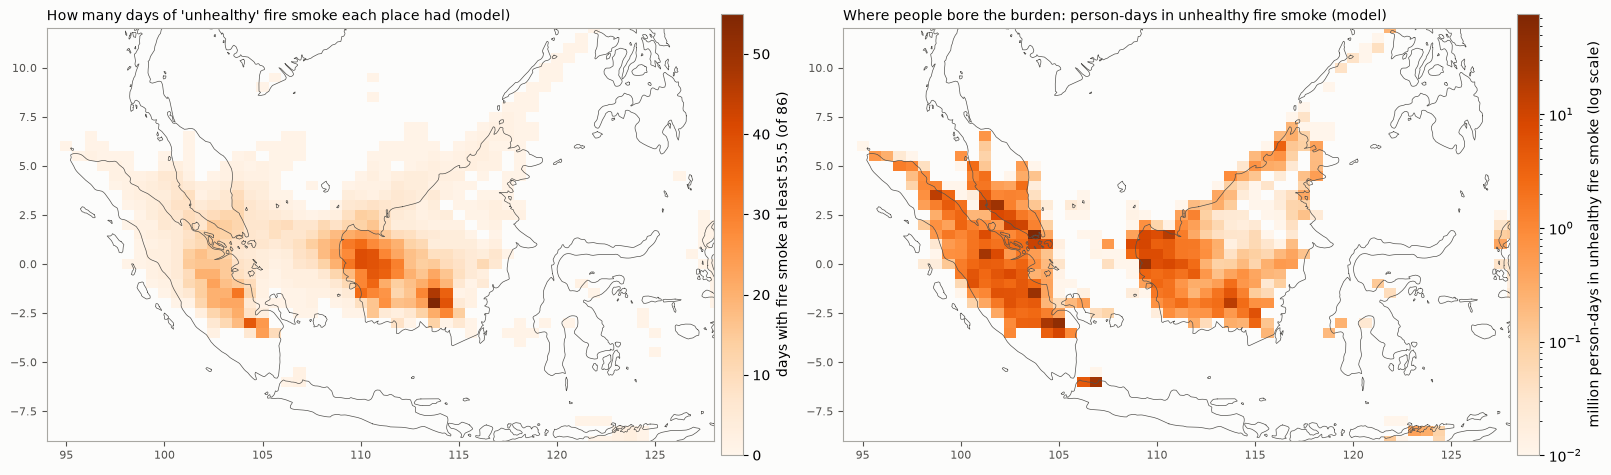

Grid cells with the most person-days in unhealthy FIRE SMOKE (model):
 lat    lon  person_days_millions  unhealthy_days
 1.5 103.75                 76.56              11
-3.0 105.00                 46.30              25
-1.5 103.75                 36.16              32
 0.0 109.38                 34.78              32
 3.0 101.88                 31.89               5
-6.0 106.88                 28.73               2
 0.5 101.25                 26.63              14
-3.0 104.38                 22.62              38


In [8]:
coast = []
for feat in json.loads((COAST_DIR / "ne_50m_coastline.geojson").read_text(encoding="utf8"))["features"]:
    g = feat["geometry"]
    coast += [np.array(c) for c in (g["coordinates"] if g["type"] == "MultiLineString" else [g["coordinates"]])]
pop_all = sum(pop_grids.values())
unhealthy_days = (geos["firesmoke"] >= LEVELS[unh]).sum("time").values
person_days = pop_all * unhealthy_days
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), constrained_layout=True)
m = axes[0].pcolormesh(G_LON, G_LAT, np.where(unhealthy_days > 0, unhealthy_days, np.nan), cmap="Oranges", vmin=0, vmax=max(1, int(unhealthy_days.max())), shading="auto")
fig.colorbar(m, ax=axes[0], shrink=0.8, pad=0.01).set_label(f"days with fire smoke at least 55.5 (of {len(DAYS)})")
axes[0].set_title("How many days of 'unhealthy' fire smoke each place had (model)", loc="left", fontsize=10)
pdm = np.where(person_days > 0, person_days / 1e6, np.nan)
m = axes[1].pcolormesh(G_LON, G_LAT, pdm, cmap="Oranges", norm=LogNorm(vmin=0.01, vmax=np.nanmax(pdm)), shading="auto")
fig.colorbar(m, ax=axes[1], shrink=0.8, pad=0.01).set_label("million person-days in unhealthy fire smoke (log scale)")
axes[1].set_title("Where people bore the burden: person-days in unhealthy fire smoke (model)", loc="left", fontsize=10)
for ax in axes:
    for line in coast:
        ax.plot(line[:, 0], line[:, 1], color="#52514e", lw=0.5)
    ax.set_xlim(MAP_EXTENT[0], MAP_EXTENT[1])
    ax.set_ylim(MAP_EXTENT[2], MAP_EXTENT[3])
    ax.set_aspect("equal")
    ax.tick_params(labelsize=8, colors="#52514e")
fig.savefig(FIG_DIR / "exposure_maps.png", dpi=110)
plt.show()
top = pd.DataFrame({"lat": np.repeat(G_LAT, len(G_LON)), "lon": np.tile(G_LON, len(G_LAT)), "person_days_millions": person_days.ravel() / 1e6, "unhealthy_days": unhealthy_days.ravel()}).sort_values("person_days_millions", ascending=False).head(8)
print("Grid cells with the most person-days in unhealthy FIRE SMOKE (model):")
print(top.round(2).to_string(index=False))

___
**END**